# HDB Rentals: combined pipeline

Everything approved so far, in one place, ending in predictions for `data/test.csv`.

| decision | source |
|---|---|
| lowercase/strip text, one spelling per `FLAT_TYPE`, drop constant `FURNISHED` and `FEE` | `01_eda_train` §4, `main` §1.1–1.2 |
| keep `MONTH_INDEX`; it holds the market level at the last training month | `01_eda_train` §7.8 |
| time-ordered validation only; report bias as well as error | `01_eda_train` §7.4–7.5 |
| join the cleaned HDB block table on `(TOWN, BLOCK, STREET)`; keep the 11 SERS blocks, `MAX_FLOOR` stays NaN | `01_eda_hdb`, `03_feature_rmse` §6 |
| distance features: 2 km counts + nearest-distance, malls, hawker centres, CBD distance | `06_distance_features` §5 |

Open question tested here: `main.ipynb` drops `FLOOR_AREA_SQM`, uses `FLAT_AGE` instead of the lease year and
merges `BLOCK`/`STREET`; `03`/`06` keep floor area and lease year. Section 4 compares both.

1. Clean the rental data
2. Block-level distance features
3. Validation scheme and reproduction check
4. Base columns: `03`/`06` vs `main.ipynb`
5. Model comparison
6. Fit on all of train, predict test
7. Summary

In [1]:
import json
from pathlib import Path

import lightgbm as lgb
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import HistGradientBoostingRegressor, RandomForestRegressor
from sklearn.impute import SimpleImputer
from sklearn.linear_model import Ridge
from sklearn.metrics import mean_absolute_error, mean_squared_error
from sklearn.model_selection import KFold
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, OrdinalEncoder, StandardScaler

pd.set_option("display.width", 160)
pd.set_option("display.float_format", lambda v: f"{v:,.2f}")
plt.rcParams["figure.dpi"] = 110

ROOT = Path("..") if Path("../data").exists() else Path(".")
DATA, CLEANED, OUT = ROOT / "data", ROOT / "cleaned", ROOT / "outputs"
OUT.mkdir(parents=True, exist_ok=True)
TARGET = "MONTHLY_RENT"
KEY = ["TOWN", "BLOCK", "STREET"]
SEED = 0

## 1. Clean the rental data

Train and test go through the same function. Only the repairs justified in `01_eda_train` §4, plus the derived
columns both base variants need.

In [2]:
FLAT_TYPE_ORDER = ["1-room", "2-room", "3-room", "4-room", "5-room", "executive"]


def lower_strip(df: pd.DataFrame) -> pd.DataFrame:
    out = df.copy()
    text = [c for c in out.columns if pd.api.types.is_string_dtype(out[c])]
    out[text] = out[text].apply(lambda s: s.str.strip().str.lower())
    return out


def clean_rent(df: pd.DataFrame) -> pd.DataFrame:
    out = lower_strip(df).drop(columns=["FURNISHED", "FEE"])
    # "4 room" and "4-room" are the same level.
    out["FLAT_TYPE"] = out["FLAT_TYPE"].str.replace(r"[\s\-]+", "-", regex=True)
    date = pd.to_datetime(out["RENT_APPROVAL_DATE"], format="%Y-%m")
    out["RENT_APPROVAL_DATE"] = date
    out["MONTH_INDEX"] = (date.dt.year - 2021) * 12 + date.dt.month - 1
    # main.ipynb's derived columns.
    out["FLAT_AGE"] = date.dt.year - out["LEASE_COMMENCE_DATE"]
    out["FLAT_TYPE_ORD"] = out["FLAT_TYPE"].map({t: i + 1 for i, t in enumerate(FLAT_TYPE_ORDER)})
    out["BLOCK_STREET"] = out["BLOCK"] + " " + out["STREET"]
    return out


train = clean_rent(pd.read_csv(DATA / "train.csv"))
test = clean_rent(pd.read_csv(DATA / "test.csv"))
assert train["FLAT_TYPE_ORD"].notna().all() and test["FLAT_TYPE_ORD"].notna().all()

for name, df in [("train", train), ("test", test)]:
    print(f"{name:<5} {len(df):>7,} rows  {df['RENT_APPROVAL_DATE'].min():%Y-%m} to "
          f"{df['RENT_APPROVAL_DATE'].max():%Y-%m}  flat types: {sorted(df['FLAT_TYPE'].unique())}")

train 150,000 rows  2021-01 to 2025-03  flat types: ['1-room', '2-room', '3-room', '4-room', '5-room', 'executive']
test   50,000 rows  2025-03 to 2026-07  flat types: ['1-room', '2-room', '3-room', '4-room', '5-room', 'executive']


## 2. Block-level distance features

Same construction as `06_distance_features` §2, built from the cleaned tables in `cleaned/` plus the raw mall and
hawker files. Planned MRT stations and hawker centres under construction are excluded. CBD = Raffles Place MRT.

In [3]:
def haversine_km(lat1, lon1, lat2, lon2):
    p1, p2 = np.radians(lat1), np.radians(lat2)
    dlat, dlon = np.radians(lat2 - lat1), np.radians(lon2 - lon1)
    a = np.sin(dlat / 2) ** 2 + np.cos(p1) * np.cos(p2) * np.sin(dlon / 2) ** 2
    return 2 * 6371.0 * np.arcsin(np.sqrt(a))


hdb = pd.read_csv(CLEANED / "sg_hdb_block_cleaned.csv", dtype={"POSTAL_CODE": str})
mrt = pd.read_csv(CLEANED / "sg_mrt_stations_cleaned.csv")
schools = pd.read_csv(CLEANED / "sg_schools_cleaned.csv")
malls = lower_strip(pd.read_csv(DATA / "auxiliary" / "sg-shopping-malls.csv"))

with open(DATA / "auxiliary" / "HawkerCentresGEOJSON.geojson") as f:
    features = json.load(f)["features"]
hawker = lower_strip(pd.DataFrame({
    "NAME": [feat["properties"]["NAME"] for feat in features],
    "STATUS": [feat["properties"]["STATUS"] for feat in features],
    "LONGITUDE": [feat["geometry"]["coordinates"][0] for feat in features],
    "LATITUDE": [feat["geometry"]["coordinates"][1] for feat in features],
}))

mrt_open = mrt[mrt["STATUS"].eq("open")].drop_duplicates("NAME")
POI_GROUPS = {
    "primary": schools[schools["MAINLEVEL_CODE"].str.contains("primary", na=False)],
    "secondary": schools[schools["MAINLEVEL_CODE"].str.contains("secondary", na=False)],
    "mrt": mrt_open,
    "mrt_interchange": mrt_open[mrt_open["IS_INTERCHANGE"]],
    "malls": malls,
    "hawker": hawker[hawker["STATUS"].ne("under construction")],
}
RADII_KM = {"1km": 1.0, "2km": 2.0}

lat, lon = hdb["LATITUDE"].to_numpy(), hdb["LONGITUDE"].to_numpy()
for prefix, poi in POI_GROUPS.items():
    d = haversine_km(lat[:, None], lon[:, None], poi["LATITUDE"].to_numpy()[None, :], poi["LONGITUDE"].to_numpy()[None, :])
    hdb[f"{prefix}_nearest_km"] = d.min(axis=1)
    for label, r in RADII_KM.items():
        hdb[f"{prefix}_within_{label}"] = (d <= r).sum(axis=1)
cbd = mrt.loc[mrt["NAME"].eq("raffles place mrt station"), ["LATITUDE", "LONGITUDE"]].iloc[0]
hdb["dist_to_cbd_km"] = haversine_km(lat, lon, cbd["LATITUDE"], cbd["LONGITUDE"])

print({k: len(v) for k, v in POI_GROUPS.items()})

{'primary': 179, 'secondary': 133, 'mrt': 192, 'mrt_interchange': 44, 'malls': 113, 'hawker': 123}


`DIST` is the best set in `06_distance_features` §4e ("2km REFERENCE + kitchen sink", +6.79 vs BASE on LightGBM).

In [4]:
DIST = [
    "MAX_FLOOR", "primary_within_2km", "mrt_within_2km",
    "primary_nearest_km", "mrt_nearest_km", "secondary_within_1km",
    "mrt_interchange_within_1km", "mrt_interchange_nearest_km",
    "malls_within_1km", "malls_nearest_km", "hawker_within_1km", "hawker_nearest_km", "dist_to_cbd_km",
]

block_cols = KEY + ["MISSING_BUILDING_INFO"] + DIST
train = train.merge(hdb[block_cols], on=KEY, how="left", validate="m:1")
test = test.merge(hdb[block_cols], on=KEY, how="left", validate="m:1")
for name, df in [("train", train), ("test", test)]:
    print(f"{name:<5} rows matched to a block: {df['MISSING_BUILDING_INFO'].notna().mean():.2%}  "
          f"SERS rows: {int(df['MISSING_BUILDING_INFO'].eq(True).sum())}")
train[DIST].describe().T[["mean", "min", "50%", "max"]]

train rows matched to a block: 100.00%  SERS rows: 159
test  rows matched to a block: 100.00%  SERS rows: 0


,mean,min,50%,max
MAX_FLOOR,15.30,2.00,13.00,50.00
primary_within_2km,8.11,0.00,7.00,20.00
mrt_within_2km,5.60,0.00,5.00,23.00
primary_nearest_km,0.43,0.02,0.37,3.31
mrt_nearest_km,0.59,0.02,0.53,2.57
secondary_within_1km,2.05,0.00,2.00,6.00
mrt_interchange_within_1km,0.45,0.00,0.00,4.00
mrt_interchange_nearest_km,1.50,0.03,1.15,6.69
malls_within_1km,1.17,0.00,1.00,12.00
malls_nearest_km,0.81,0.00,0.73,3.20


## 3. Validation scheme and reproduction check

Three forecast origins, each trained on every month up to the origin and scored on the next 16 months, the same
distance as the real test window (2025-03 to 2026-07). The last fold (plateau) is the closest to the test window.

In [5]:
ORIGINS = ["2021-12", "2022-11", "2023-11"]
HORIZON = 16


def time_folds(df):
    for origin in ORIGINS:
        cut = pd.Timestamp(origin)
        end = cut + pd.DateOffset(months=HORIZON)
        date = df["RENT_APPROVAL_DATE"]
        yield origin, df[date <= cut], df[(date > cut) & (date <= end)]


for origin, f, v in time_folds(train):
    print(f"origin {origin}: train {len(f):>7,} rows | holdout {v['RENT_APPROVAL_DATE'].min():%Y-%m} to "
          f"{v['RENT_APPROVAL_DATE'].max():%Y-%m}, {len(v):>6,} rows")

origin 2021-12: train  37,619 rows | holdout 2022-01 to 2023-04, 44,305 rows
origin 2022-11: train  67,494 rows | holdout 2022-12 to 2024-03, 47,348 rows
origin 2023-11: train 102,829 rows | holdout 2023-12 to 2025-03, 47,171 rows


**Feature specs and models.** A spec lists numeric and categorical columns, and optionally a `BLOCK_STREET`
premium (below). Every model gets the same columns; only the encoding differs:

- **Ridge:** median-impute and scale numerics, one-hot categoricals.
- **Random forest, HistGradientBoosting:** ordinal-coded categoricals (native categorical splits for HGB).
- **LightGBM:** native categoricals, NaN left missing. Same settings as `03`/`06`.

`BLOCK_STREET` has ~9,400 levels, too many to one-hot. It enters as a smoothed target encoding of **relative
rent** (rent ÷ that month's median), so the encoding carries the block's premium and not the market level of the
months it was seen in (`01_eda_train` §7.3, §8). Training rows are encoded out-of-fold; holdout and test rows
use all training rows; unseen blocks get the prior.

In [6]:
def block_premium(fit_df, apply_df=None, m=20, n_splits=5):
    rel = fit_df[TARGET] / fit_df.groupby("MONTH_INDEX")[TARGET].transform("median")

    def encode(keys_fit, rel_fit, keys_apply):
        prior = rel_fit.mean()
        agg = rel_fit.groupby(keys_fit).agg(["count", "mean"])
        smooth = (agg["count"] * agg["mean"] + m * prior) / (agg["count"] + m)
        return keys_apply.map(smooth).fillna(prior).to_numpy()

    if apply_df is not None:
        return encode(fit_df["BLOCK_STREET"], rel, apply_df["BLOCK_STREET"])
    oof = np.empty(len(fit_df))
    for fit_idx, enc_idx in KFold(n_splits, shuffle=True, random_state=SEED).split(fit_df):
        keys = fit_df["BLOCK_STREET"]
        oof[enc_idx] = encode(keys.iloc[fit_idx], rel.iloc[fit_idx], keys.iloc[enc_idx])
    return oof


def design(spec, fit_df, apply_df):
    cols = spec["num"] + spec["cat"]
    Xf, Xa = fit_df[cols].copy(), apply_df[cols].copy()
    num = list(spec["num"])
    if spec.get("block_premium"):
        Xf["BLOCK_PREMIUM"], Xa["BLOCK_PREMIUM"] = block_premium(fit_df), block_premium(fit_df, apply_df)
        num.append("BLOCK_PREMIUM")
    return Xf, Xa, num, spec["cat"]


def make_ridge(num, cat):
    pre = ColumnTransformer([
        ("num", Pipeline([("imp", SimpleImputer(strategy="median")), ("sc", StandardScaler())]), num),
        ("cat", OneHotEncoder(handle_unknown="ignore"), cat),
    ])
    return Pipeline([("pre", pre), ("m", Ridge(alpha=1.0))])


def ordinal_pre(num, cat):
    return ColumnTransformer([
        ("cat", OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=-1), cat),
        ("num", "passthrough", num),
    ])


def make_rf(num, cat):
    rf = RandomForestRegressor(n_estimators=200, min_samples_leaf=5, max_features=0.5, n_jobs=-1, random_state=SEED)
    return Pipeline([("pre", ordinal_pre(num, cat)), ("m", rf)])


def make_hgb(num, cat):
    hgb = HistGradientBoostingRegressor(
        max_iter=400, learning_rate=0.05, categorical_features=list(range(len(cat))), random_state=SEED,
    )
    return Pipeline([("pre", ordinal_pre(num, cat)), ("m", hgb)])


def fit_predict(model, spec, fit_df, apply_df):
    Xf, Xa, num, cat = design(spec, fit_df, apply_df)
    if model == "LightGBM":
        for c in cat:
            Xf[c] = Xf[c].astype("category")
            cats = Xf[c].cat.categories
            Xa[c] = pd.Categorical(Xa[c].where(Xa[c].isin(cats)), categories=cats)  # unseen level -> missing
        est = lgb.LGBMRegressor(n_estimators=400, learning_rate=0.05, num_leaves=31, verbose=-1, n_jobs=-1,
                                random_state=SEED)
        est.fit(Xf, fit_df[TARGET], categorical_feature=cat)
    else:
        est = {"Ridge": make_ridge, "Random forest": make_rf, "HistGradientBoosting": make_hgb}[model](num, cat)
        est.fit(Xf, fit_df[TARGET])
    return est.predict(Xa)


def score(y, pred):
    return {"rmse": float(np.sqrt(mean_squared_error(y, pred))), "mae": mean_absolute_error(y, pred),
            "bias": float(np.mean(pred - y))}


def evaluate(model, spec_name, spec):
    rows = []
    for origin, f, v in time_folds(train):
        rows.append({"model": model, "spec": spec_name, "origin": origin,
                     **score(v[TARGET].to_numpy(), fit_predict(model, spec, f, v))})
    return rows

**Reproduction check.** On `06`'s single split (fit 2021-01 to 2023-12, score 2024-01 to 2025-03), LightGBM
should give BASE ≈ 496.4 and BASE + `DIST` ≈ 489.6 (496.4 − 6.79).

In [7]:
SPEC_0306 = {"num": ["FLOOR_AREA_SQM", "LEASE_COMMENCE_DATE", "MONTH_INDEX"], "cat": ["TOWN", "FLAT_TYPE", "FLAT_MODEL"]}
with_dist = lambda spec: {**spec, "num": spec["num"] + DIST}

cut = pd.Timestamp("2024-01-01")
fit_06, val_06 = train[train["RENT_APPROVAL_DATE"] < cut], train[train["RENT_APPROVAL_DATE"] >= cut]
pd.DataFrame({
    name: score(val_06[TARGET].to_numpy(), fit_predict("LightGBM", spec, fit_06, val_06))
    for name, spec in [("BASE", SPEC_0306), ("BASE + DIST", with_dist(SPEC_0306))]
}).T

,rmse,mae,bias
BASE,496.37,372.43,-35.98
BASE + DIST,489.58,366.51,-38.11


## 4. Base columns: `03`/`06` vs `main.ipynb`

| spec | numeric | categorical |
|---|---|---|
| `03/06` | `FLOOR_AREA_SQM`, `LEASE_COMMENCE_DATE`, `MONTH_INDEX` | `TOWN`, `FLAT_TYPE`, `FLAT_MODEL` |
| `main` | `FLAT_TYPE_ORD`, `FLAT_AGE`, `MONTH_INDEX` | `TOWN`, `FLAT_MODEL` |
| `main + BLOCK_STREET` | as `main`, plus the `BLOCK_STREET` premium | as `main` |

`main.ipynb` has no time column; `MONTH_INDEX` is added to it per `01_eda_train` §7.8. Each spec is scored with and
without `DIST`, on LightGBM, across the three folds.

In [8]:
SPEC_MAIN = {"num": ["FLAT_TYPE_ORD", "FLAT_AGE", "MONTH_INDEX"], "cat": ["TOWN", "FLAT_MODEL"]}
SPEC_MAIN_BLOCK = {**SPEC_MAIN, "block_premium": True}
BASE_SPECS = {"03/06": SPEC_0306, "main": SPEC_MAIN, "main + BLOCK_STREET": SPEC_MAIN_BLOCK}

base_rows = []
for name, spec in BASE_SPECS.items():
    base_rows += evaluate("LightGBM", name, spec)
    base_rows += evaluate("LightGBM", f"{name} + DIST", with_dist(spec))
base_results = pd.DataFrame(base_rows)

base_table = base_results.pivot(index="spec", columns="origin", values=["rmse", "bias"])
base_table[("rmse", "mean")] = base_results.groupby("spec")["rmse"].mean()
base_table.sort_values(("rmse", "mean"))

rmse                    bias                   rmse
origin                     2021-12 2022-11 2023-11 2021-12 2022-11 2023-11   mean
spec                                                                             
03/06 + DIST                738.14  639.77  493.90 -417.58 -200.74  -43.98 623.93
main + BLOCK_STREET + DIST  745.32  638.07  493.61 -425.17 -204.60  -48.60 625.67
main + BLOCK_STREET         744.20  636.95  497.70 -420.94 -194.51  -43.90 626.28
main + DIST                 742.44  642.03  495.23 -422.07 -206.39  -50.43 626.57
03/06                       741.86  640.13  500.61 -417.07 -194.48  -42.73 627.53
main                        744.26  645.16  507.48 -418.42 -196.26  -50.24 632.30

In [9]:
dist_specs = [f"{name} + DIST" for name in BASE_SPECS]
BEST_BASE = base_results[base_results["spec"].isin(dist_specs)].groupby("spec")["rmse"].mean().idxmin()
BEST_SPEC = with_dist(BASE_SPECS[BEST_BASE.removesuffix(" + DIST")])
print("chosen spec:", BEST_BASE)
print("  numeric    :", BEST_SPEC["num"] + (["BLOCK_PREMIUM"] if BEST_SPEC.get("block_premium") else []))
print("  categorical:", BEST_SPEC["cat"])

chosen spec: 03/06 + DIST
  numeric    : ['FLOOR_AREA_SQM', 'LEASE_COMMENCE_DATE', 'MONTH_INDEX', 'MAX_FLOOR', 'primary_within_2km', 'mrt_within_2km', 'primary_nearest_km', 'mrt_nearest_km', 'secondary_within_1km', 'mrt_interchange_within_1km', 'mrt_interchange_nearest_km', 'malls_within_1km', 'malls_nearest_km', 'hawker_within_1km', 'hawker_nearest_km', 'dist_to_cbd_km']
  categorical: ['TOWN', 'FLAT_TYPE', 'FLAT_MODEL']


- **The spec matters far less than the fold.** All six specs sit within 9 of each other on mean RMSE; the market
  regime moves error by ~250 between folds.
- **`03/06 + DIST` is best** on mean RMSE (623.9). On the plateau fold it ties `main + BLOCK_STREET + DIST`
  (493.9 vs 493.6).
- **`DIST` helps on every fold:** 741.9 → 738.1, 640.1 → 639.8, 500.6 → 493.9. The plateau-fold gain (6.7) matches
  `06`'s +6.79 on a similar split; on the 2022-11 fold it is almost nothing.
- **`main.ipynb`'s column drops cost a little with trees:** 632.3 vs 627.5 without `DIST`, 626.6 vs 623.9 with it.
  Its ablation used a two-feature linear regression, where floor area and flat type are interchangeable; a tree
  uses both.
- **The `BLOCK_STREET` premium is redundant once `DIST` is in:** it improves `main` by 6.0 on its own but adds 0.9
  on top of `DIST`. Block coordinates already carry most of what the block identity says. Not kept.

## 5. Model comparison

Chosen spec, four model families, same three folds.

In [10]:
MODELS = ["Ridge", "Random forest", "HistGradientBoosting", "LightGBM"]
model_results = pd.DataFrame([row for model in MODELS for row in evaluate(model, BEST_BASE, BEST_SPEC)])

model_table = model_results.pivot(index="model", columns="origin", values=["rmse", "bias"])
model_table[("rmse", "mean")] = model_results.groupby("model")["rmse"].mean()
model_table[("mae", "mean")] = model_results.groupby("model")["mae"].mean()
model_table.sort_values(("rmse", "mean"))

rmse                    bias                   rmse    mae
origin               2021-12 2022-11 2023-11 2021-12 2022-11 2023-11   mean   mean
model                                                                             
LightGBM              738.14  639.77  493.90 -417.58 -200.74  -43.98 623.93 488.44
HistGradientBoosting  744.24  637.20  494.93 -425.61 -203.18  -42.01 625.46 489.87
Random forest         755.01  660.12  509.39 -441.02 -226.17  -44.03 641.51 501.46
Ridge                 665.40  629.16  661.17 -312.69  -87.43  395.87 651.91 506.70

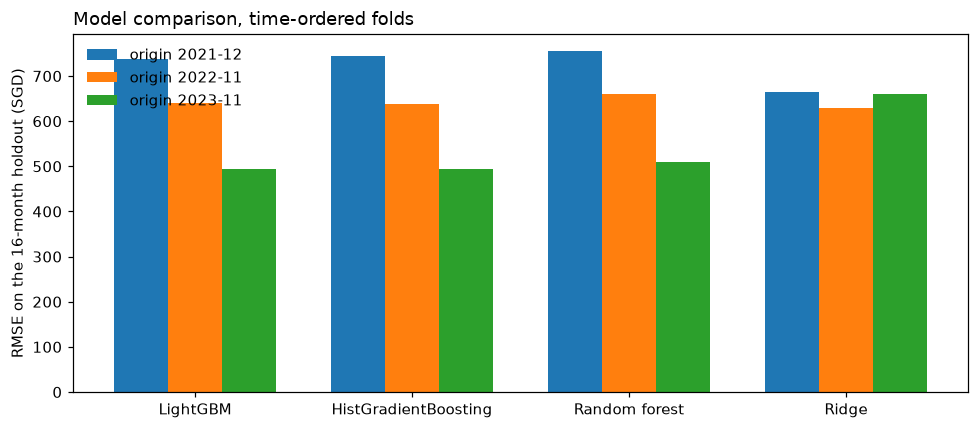

In [11]:
fig, ax = plt.subplots(figsize=(9, 4))
order = model_results.groupby("model")["rmse"].mean().sort_values().index
width = 0.25
for i, origin in enumerate(ORIGINS):
    vals = model_results[model_results["origin"] == origin].set_index("model").loc[order, "rmse"]
    ax.bar(np.arange(len(order)) + (i - 1) * width, vals, width=width, label=f"origin {origin}")
ax.set_xticks(np.arange(len(order)), order)
ax.set_ylabel("RMSE on the 16-month holdout (SGD)")
ax.set_title("Model comparison, time-ordered folds", loc="left")
ax.legend(frameon=False)
plt.tight_layout()
plt.show()

- **LightGBM is best** on mean RMSE (623.9) and on the plateau fold (493.9). HistGradientBoosting is within 1.5,
  effectively a tie: one seed, no tuning.
- **Random forest** is worse on every fold (+17.6 on mean).
- **Ridge is best while the market grows and worst once it stops.** A linear `MONTH_INDEX` extends the trend: it
  wins the 2021-12 fold (665 vs 738, bias −313 vs −418) and loses the plateau fold by 167 (bias +396). The trees
  hold the last level instead: large under-prediction in the growth years, near-zero bias on the plateau. Same
  behaviour as `01_eda_train` §7.6.
- No model choice here moves error as much as the level assumption does.

## 6. Fit on all of train, predict test

The best model by mean RMSE is refit on 2021-01 to 2025-03 and predicts the 50,000 test rows, in the file's own
row order (the test file has no ID column).

**Level assumption:** with `MONTH_INDEX`, every test month is treated as 2025-03, so these predictions hold rent
at its early-2025 level through 2026-07 (`01_eda_train` §7.8).

In [12]:
BEST_MODEL = model_results.groupby("model")["rmse"].mean().idxmin()
test_pred = fit_predict(BEST_MODEL, BEST_SPEC, train, test)

submission = pd.DataFrame({TARGET: test_pred})
submission.to_csv(OUT / "submission.csv", index=False)
print(f"{BEST_MODEL} on {BEST_BASE}: wrote {OUT / 'submission.csv'} ({len(submission):,} rows)")

last_months = train[train["RENT_APPROVAL_DATE"] >= "2025-01-01"]
pd.DataFrame({
    "train 2025-01 to 2025-03 (actual)": last_months[TARGET].describe(),
    "test (predicted)": submission[TARGET].describe(),
}).T[["count", "mean", "25%", "50%", "75%"]]

LightGBM on 03/06 + DIST: wrote ..\outputs\submission.csv (50,000 rows)


,count,mean,25%,50%,75%
train 2025-01 to 2025-03 (actual),"8,924.00","3,142.46","2,800.00","3,150.00","3,500.00"
test (predicted),"50,000.00","3,154.24","2,809.24","3,147.72","3,422.09"


## 7. Summary

- **Pipeline:** clean → join 13 block-level `DIST` features (100% of train and test rows match a block) →
  LightGBM on the `03/06` base columns + `DIST` → `outputs/submission.csv`.
- **Reproduces `06`:** BASE 496.4, BASE + `DIST` 489.6 on its single split.
- **Time-ordered validation** (3 origins × 16 months): mean RMSE 623.9; the plateau fold, closest to the test
  window, 493.9 with bias −44.
- **Base columns:** keep floor area and lease year (`03/06`). `main.ipynb`'s drops cost 2.6 to 4.8 RMSE; the
  `BLOCK_STREET` premium adds under 1 once `DIST` is in.
- **Models:** LightGBM ≈ HistGradientBoosting > random forest > Ridge. Ridge wins only while the market grows.
- **Test predictions** hold the early-2025 level: median 3,148 against an actual 3,150 in 2025-01 to 2025-03.
- **Next:** stress-test the level assumption (predictions ±3% and ±5%); tune LightGBM (one configuration and one
  seed so far).